# 05 — Mel-spectrograms: checks and what they show

`src/spectrograms.py` (decision D16) computed one log-Mel spectrogram per clip and stored all of them in `data/spectrograms/mel128.npy`, with `mel128_index.csv` mapping each row to its song. The CNN (`src/train_cnn.py`) reads only these files, so before interpreting the CNN results this notebook checks that:

1. the stored array has the expected size, settings and value range;
2. each row really belongs to the song the index says, by recomputing a few clips from the original MP3 files and comparing;
3. the padding of short clips looks as decided (D04).

It then describes the data the CNN learns from: one example per quadrant, the average spectrum of each quadrant, and the difference between Q3 (sad) and Q4 (calm), the pair the models confuse most. The descriptive part uses the **training set of protocol A** only, as in `03_valence_features.ipynb`.

Figures and tables are saved to `results/spectrograms/`.

In [ ]:
import json
import sys
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from spectrograms import CONFIG, mel

%matplotlib inline

SPEC = ROOT / "data" / "spectrograms"
DATASET = ROOT / "data" / "raw" / "MERGE_Audio_Balanced"
SPLIT = DATASET / "tvt_dataframes" / "tvt_70_15_15" / "tvt_70_15_15_train_audio_balanced.csv"
OUT = ROOT / "results" / "spectrograms"
OUT.mkdir(parents=True, exist_ok=True)

QUADRANTS = ["Q1", "Q2", "Q3", "Q4"]
NAMES = {"Q1": "Q1 happy", "Q2": "Q2 angry/tense", "Q3": "Q3 sad", "Q4": "Q4 calm"}
COLORS = {"Q1": "#E69F00", "Q2": "#D55E00", "Q3": "#0072B2", "Q4": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})
summary = {}


def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    plt.show()


info = json.loads((SPEC / "mel128.json").read_text(encoding="utf-8"))
index = pd.read_csv(SPEC / "mel128_index.csv", dtype={"Song": str})
data = np.load(SPEC / "mel128.npy", mmap_mode="r")
freqs = librosa.mel_frequencies(n_mels=CONFIG["n_mels"], fmin=CONFIG["fmin"], fmax=CONFIG["fmax"])

## 1. Size, settings and value range

In [ ]:
checks = {
    "array shape": str(data.shape),
    "array dtype": str(data.dtype),
    "rows in index": len(index),
    "rows computed without error": int(index["ok"].sum()),
    "songs per quadrant": index["Quadrant"].value_counts().sort_index().to_dict(),
    "file size (MB)": info["size_mb"],
    "settings": {k: CONFIG[k] for k in ["sample_rate", "n_fft", "hop_length", "n_mels", "fmax", "db_reference", "dtype"]},
    "seconds per frame": round(info["seconds_per_frame"], 4),
    "value range (dB)": [round(info["db_min"], 1), round(info["db_max"], 1)],
    "mean value (dB)": round(info["db_mean"], 1),
    "settings in the file match the script": info["config"] == CONFIG,
    "errors file present": (SPEC / "mel128_errors.csv").exists(),
}
summary["checks"] = checks
checks

{'array shape': '(3232, 128, 1292)',
 'array dtype': 'float16',
 'rows in index': 3232,
 'rows computed without error': 3232,
 'songs per quadrant': {'Q1': 808, 'Q2': 808, 'Q3': 808, 'Q4': 808},
 'file size (MB)': 1069.0,
 'settings': {'sample_rate': 22050,
  'n_fft': 2048,
  'hop_length': 512,
  'n_mels': 128,
  'fmax': 11025,
  'db_reference': 1.0,
  'dtype': 'float16'},
 'seconds per frame': 0.0232,
 'value range (dB)': [-100.0, 41.3],
 'mean value (dB)': -13.4,
 'settings in the file match the script': True,
 'errors file present': False}

## 2. Does each row belong to the right song?

The images in `data/spectrograms/png/` and the array are written separately, so looking at the images does not prove that row *i* of the array is the song listed on row *i* of the index. Here six clips are recomputed from their MP3 files with exactly the same function (`mel` from `src/spectrograms.py`) and compared with the stored rows: one clip per quadrant and the two shortest clips of the dataset (4.8 s and 10.1 s), which also check the padding. If the rows were shifted or mixed, the difference would be tens of dB; if they are correct, it is limited to the rounding of `float16` (a few hundredths of a dB).

In [ ]:
check_songs = {"A005": "Q1", "A010": "Q2", "A003": "Q3", "A001": "Q4", "MT0002054074": "Q4", "MT0013621344": "Q1"}
rows = []
by_song = index.set_index("Song")
for song, quadrant in check_songs.items():
    fresh, seconds = mel(DATASET / quadrant / f"{song}.mp3", CONFIG)
    stored = np.asarray(data[int(by_song.loc[song, "row"])])
    rows.append({"Song": song, "Quadrant": by_song.loc[song, "Quadrant"], "seconds_loaded": round(seconds, 2),
                 "index_seconds": round(float(by_song.loc[song, "duration_loaded"]), 2),
                 "max_abs_difference_dB": float(np.abs(fresh.astype(np.float32) - stored.astype(np.float32)).max()),
                 "mean_abs_difference_dB": float(np.abs(fresh.astype(np.float32) - stored.astype(np.float32)).mean())})
integrity = pd.DataFrame(rows)
integrity.to_csv(OUT / "02_row_check.csv", index=False)
summary["row_check_max_difference_dB"] = round(float(integrity["max_abs_difference_dB"].max()), 4)
integrity.round(4)

,Song,Quadrant,seconds_loaded,index_seconds,max_abs_difference_dB,mean_abs_difference_dB
0,A005,Q1,30.00,30.00,0.0005,0.0
1,A010,Q2,30.00,30.00,0.0039,0.0
2,A003,Q3,30.00,30.00,0.0078,0.0
3,A001,Q4,30.00,30.00,0.0312,0.0
4,MT0002054074,Q4,4.75,4.75,0.0078,0.0
5,MT0013621344,Q1,10.08,10.08,0.0010,0.0


## 3. What a spectrogram looks like for each quadrant

One clip per quadrant. Time runs from left to right (30 s), pitch from bottom (bass) to top (about 11 kHz) on the Mel scale, and colour is loudness in dB. These four clips are examples, not averages: section 4 shows what holds across the training set.

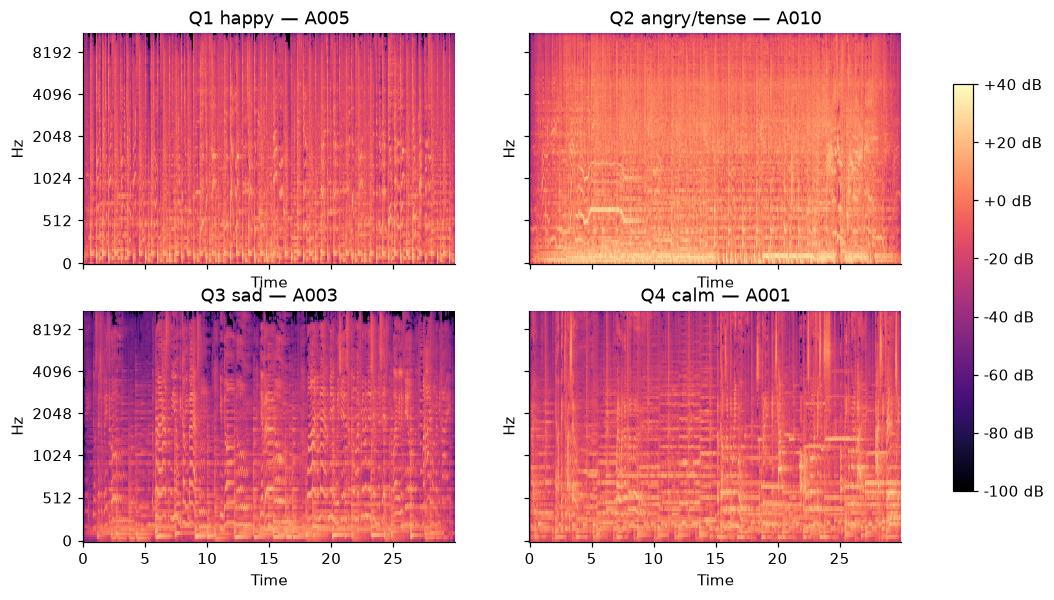

In [ ]:
examples = {"Q1": "A005", "Q2": "A010", "Q3": "A003", "Q4": "A001"}
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
for ax, (q, song) in zip(axes.ravel(), examples.items()):
    img = librosa.display.specshow(np.asarray(data[int(by_song.loc[song, "row"])], dtype=np.float32), sr=CONFIG["sample_rate"],
                                   hop_length=CONFIG["hop_length"], x_axis="time", y_axis="mel", fmax=CONFIG["fmax"], ax=ax,
                                   cmap="magma", vmin=-100, vmax=40)
    ax.set_title(f"{NAMES[q]} — {song}")
fig.colorbar(img, ax=axes, format="%+.0f dB", shrink=0.8)
fig.savefig(OUT / "03_examples_by_quadrant.png", bbox_inches="tight")
plt.show()

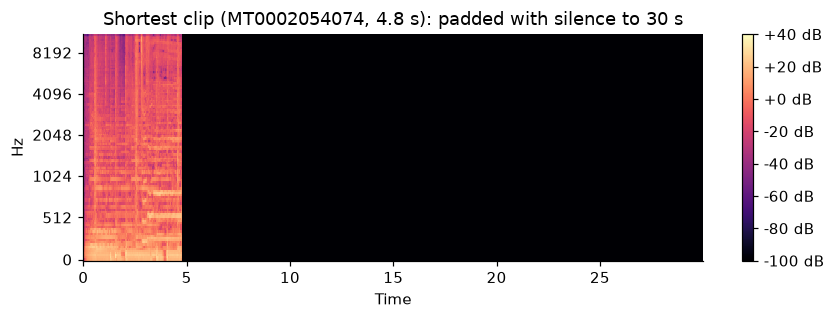

{'under_29_s': 72,
 '29_to_29.95_s': 999,
 'max_padding_frames_for_29_s_or_more': 42}

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3))
song = "MT0002054074"
img = librosa.display.specshow(np.asarray(data[int(by_song.loc[song, "row"])], dtype=np.float32), sr=CONFIG["sample_rate"],
                               hop_length=CONFIG["hop_length"], x_axis="time", y_axis="mel", fmax=CONFIG["fmax"], ax=ax, cmap="magma", vmin=-100, vmax=40)
ax.set_title(f"Shortest clip ({song}, {by_song.loc[song, 'duration_loaded']:.1f} s): padded with silence to 30 s")
fig.colorbar(img, ax=ax, format="%+.0f dB")
save(fig, "03_padding_example")
short = index[index["duration_loaded"] < 29.95]
summary["padded_clips"] = {"under_29_s": int((index["duration_loaded"] < 29).sum()), "29_to_29.95_s": int(((index["duration_loaded"] >= 29) & (index["duration_loaded"] < 29.95)).sum()),
                           "max_padding_frames_for_29_s_or_more": int(np.ceil((30 - short[short.duration_loaded >= 29]["duration_loaded"].min()) / info["seconds_per_frame"]))}
summary["padded_clips"]

## 4. The average spectrum of each quadrant (training set, protocol A)

For each training clip, the loudness of every Mel band is averaged over time, using only the frames that contain audio (the silence added to short clips is excluded). The curves below are the averages of these per-clip spectra for each quadrant, with a 95 % confidence band. Differences between the curves are the information that is directly visible in the spectrogram, before any learning.

In [ ]:
train_songs = pd.read_csv(SPLIT, dtype={"Song": str})["Song"]
train = by_song.loc[train_songs].reset_index()
n_frames_valid = np.minimum(data.shape[2], np.ceil(train["duration_loaded"].to_numpy() / info["seconds_per_frame"]).astype(int) + 1)
band_mean = np.zeros((len(train), data.shape[1]), dtype=np.float32)
loudness_mean = np.zeros(len(train), dtype=np.float32)
loudness_std = np.zeros(len(train), dtype=np.float32)
for k, (row, n) in enumerate(zip(train["row"].to_numpy(), n_frames_valid)):
    S = np.asarray(data[int(row), :, :n], dtype=np.float32)
    band_mean[k] = S.mean(axis=1)
    frame_loudness = S.mean(axis=0)
    loudness_mean[k] = frame_loudness.mean()
    loudness_std[k] = frame_loudness.std()
train = train.assign(loudness_mean=loudness_mean, loudness_std=loudness_std)
print(f"{len(train)} training clips, {train['Quadrant'].value_counts().sort_index().to_dict()}")

2264 training clips, {'Q1': 566, 'Q2': 566, 'Q3': 566, 'Q4': 566}


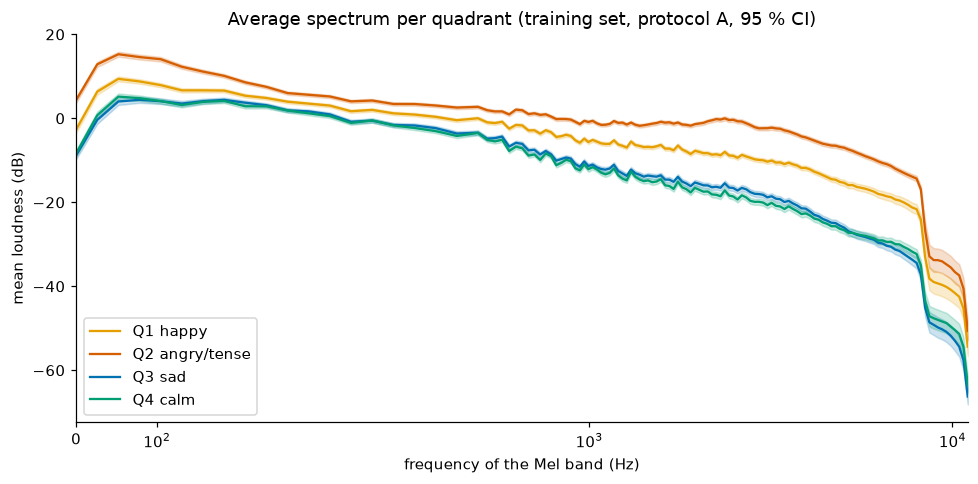

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
spectra = {}
for q in QUADRANTS:
    m = band_mean[train["Quadrant"].to_numpy() == q]
    mean, sem = m.mean(axis=0), m.std(axis=0, ddof=1) / np.sqrt(len(m))
    spectra[q] = mean
    ax.plot(freqs, mean, color=COLORS[q], label=NAMES[q])
    ax.fill_between(freqs, mean - 1.96 * sem, mean + 1.96 * sem, color=COLORS[q], alpha=0.2)
ax.set_xscale("symlog", linthresh=500)
ax.set_xlim(0, freqs.max())
ax.set_xlabel("frequency of the Mel band (Hz)")
ax.set_ylabel("mean loudness (dB)")
ax.set_title("Average spectrum per quadrant (training set, protocol A, 95 % CI)")
ax.legend()
save(fig, "04_mean_spectrum_by_quadrant")
pd.DataFrame(spectra, index=np.round(freqs, 1)).rename_axis("band_hz").round(2).to_csv(OUT / "04_mean_spectrum_by_quadrant.csv")

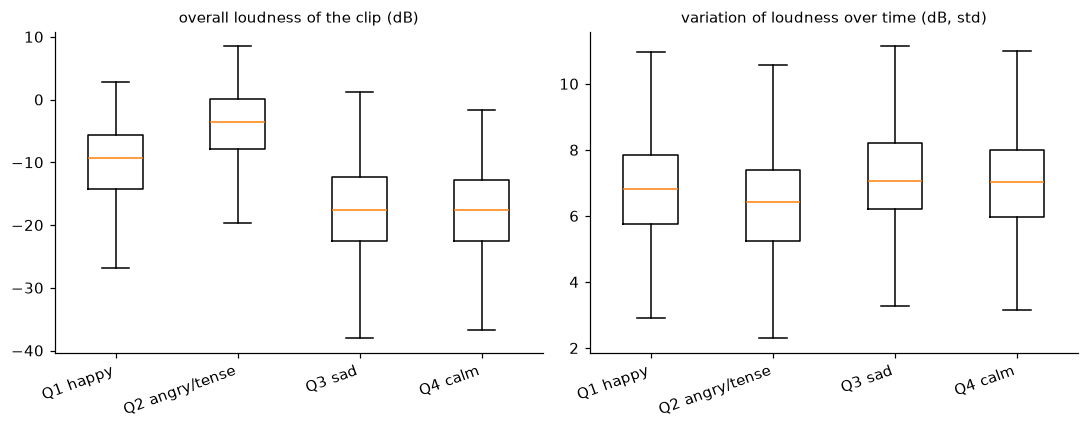

,loudness_mean,loudness_std
Quadrant,,
Q1,-9.300000,6.82
Q2,-3.650000,6.43
Q3,-17.620001,7.06
Q4,-17.549999,7.03


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col, title in zip(axes, ["loudness_mean", "loudness_std"], ["overall loudness of the clip (dB)", "variation of loudness over time (dB, std)"]):
    ax.boxplot([train.loc[train.Quadrant == q, col] for q in QUADRANTS], tick_labels=[NAMES[q] for q in QUADRANTS], showfliers=False)
    ax.set_title(title, fontsize=10)
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
save(fig, "04_loudness_by_quadrant")
loud = train.groupby("Quadrant")[["loudness_mean", "loudness_std"]].median()
loud.round(2).to_csv(OUT / "04_loudness_by_quadrant.csv")
summary["median_loudness_dB"] = loud["loudness_mean"].round(1).to_dict()
loud.round(2)

## 5. Sad vs calm: where in the spectrum do Q3 and Q4 differ?

For every Mel band, the difference between the average Q3 and Q4 spectra with a 95 % confidence interval (Welch). For scale, the same difference is shown between the high- and low-arousal halves of the model (Q1 + Q2 against Q3 + Q4), which the models separate well. If the Q3 − Q4 curve stays close to zero while the arousal curve is far from it, the spectrum alone carries little of what distinguishes sad from calm music, which is consistent with the Q3/Q4 confusion of every model.

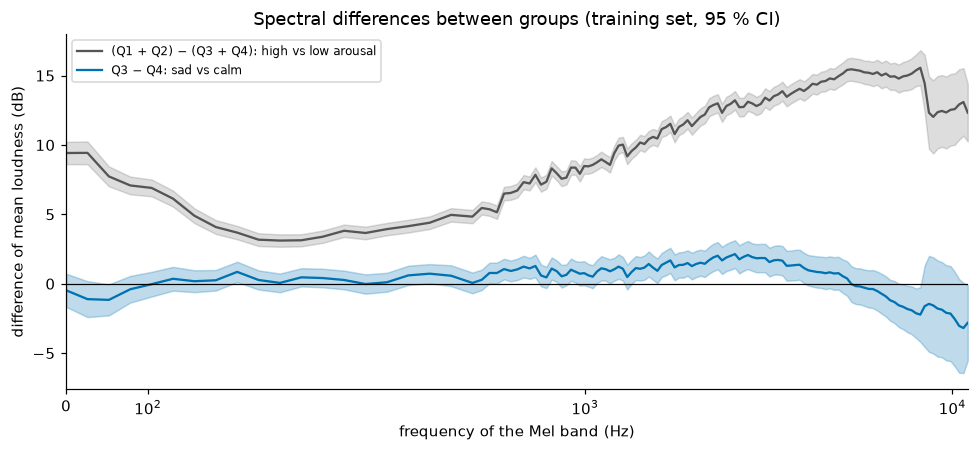

({'max_abs_dB': 3.19, 'bands_with_ci_excluding_0': 68, 'mean_dB': 0.44},
 {'max_abs_dB': 15.56, 'bands_with_ci_excluding_0': 128, 'mean_dB': 10.75})

In [ ]:
quad = train["Quadrant"].to_numpy()


def band_difference(a_mask, b_mask):
    a, b = band_mean[a_mask], band_mean[b_mask]
    diff = a.mean(axis=0) - b.mean(axis=0)
    se = np.sqrt(a.var(axis=0, ddof=1) / len(a) + b.var(axis=0, ddof=1) / len(b))
    return diff, 1.96 * se


d34, ci34 = band_difference(quad == "Q3", quad == "Q4")
d_ar, ci_ar = band_difference(np.isin(quad, ["Q1", "Q2"]), np.isin(quad, ["Q3", "Q4"]))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(freqs, d_ar, color="#555555", label="(Q1 + Q2) − (Q3 + Q4): high vs low arousal")
ax.fill_between(freqs, d_ar - ci_ar, d_ar + ci_ar, color="#555555", alpha=0.2)
ax.plot(freqs, d34, color="#0072B2", label="Q3 − Q4: sad vs calm")
ax.fill_between(freqs, d34 - ci34, d34 + ci34, color="#0072B2", alpha=0.25)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xscale("symlog", linthresh=500)
ax.set_xlim(0, freqs.max())
ax.set_xlabel("frequency of the Mel band (Hz)")
ax.set_ylabel("difference of mean loudness (dB)")
ax.set_title("Spectral differences between groups (training set, 95 % CI)")
ax.legend(fontsize=8)
save(fig, "05_q3_vs_q4_spectrum")
diffs = pd.DataFrame({"band_hz": np.round(freqs, 1), "q3_minus_q4": d34, "q3_minus_q4_ci": ci34, "arousal_difference": d_ar, "arousal_ci": ci_ar})
diffs.round(3).to_csv(OUT / "05_band_differences.csv", index=False)
summary["q3_minus_q4"] = {"max_abs_dB": round(float(np.abs(d34).max()), 2), "bands_with_ci_excluding_0": int((np.abs(d34) > ci34).sum()),
                          "mean_dB": round(float(d34.mean()), 2)}
summary["arousal_difference"] = {"max_abs_dB": round(float(np.abs(d_ar).max()), 2), "bands_with_ci_excluding_0": int((np.abs(d_ar) > ci_ar).sum()),
                                 "mean_dB": round(float(d_ar.mean()), 2)}
summary["q3_minus_q4"], summary["arousal_difference"]

## 6. Summary of the numbers used in the findings

In [ ]:
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
summary

{'checks': {'array shape': '(3232, 128, 1292)',
  'array dtype': 'float16',
  'rows in index': 3232,
  'rows computed without error': 3232,
  'songs per quadrant': {'Q1': 808, 'Q2': 808, 'Q3': 808, 'Q4': 808},
  'file size (MB)': 1069.0,
  'settings': {'sample_rate': 22050,
   'n_fft': 2048,
   'hop_length': 512,
   'n_mels': 128,
   'fmax': 11025,
   'db_reference': 1.0,
   'dtype': 'float16'},
  'seconds per frame': 0.0232,
  'value range (dB)': [-100.0, 41.3],
  'mean value (dB)': -13.4,
  'settings in the file match the script': True,
  'errors file present': False},
 'row_check_max_difference_dB': 0.0312,
 'padded_clips': {'under_29_s': 72,
  '29_to_29.95_s': 999,
  'max_padding_frames_for_29_s_or_more': 42},
 'median_loudness_dB': {'Q1': -9.300000190734863,
  'Q2': -3.5999999046325684,
  'Q3': -17.600000381469727,
  'Q4': -17.5},
 'q3_minus_q4': {'max_abs_dB': 3.19,
  'bands_with_ci_excluding_0': 68,
  'mean_dB': 0.44},
 'arousal_difference': {'max_abs_dB': 15.56,
  'bands_with_c

## 7. Findings

**1. The stored spectrograms are complete and correctly aligned with the songs.** All 3,232 clips were computed without error (808 per quadrant), with the settings of D16. The six clips recomputed from their MP3 files (one per quadrant and the two shortest) match the stored rows with a mean absolute difference of 0.0 dB and a maximum of 0.03 dB, which is the rounding of `float16` at these magnitudes. A shifted or mixed row would differ by tens of dB. The CNN therefore learns from the right spectrogram for every song.

**2. Padding is negligible except for a few clips.** 72 clips are shorter than 29 s; 999 lose less than one second (at most 42 of 1,292 frames, about 3 %) and are padded with silence; only four clips are very short (4.8–10.1 s), as already found in `01_eda.ipynb`.

**3. Loudness separates arousal, not valence.** The median loudness of a clip is −3.6 dB for Q2 and −9.3 dB for Q1, but −17.6 dB for Q3 and −17.5 dB for Q4. High-arousal music is louder in every one of the 128 Mel bands (the 95 % interval excludes zero in all of them), by 10.8 dB on average and up to 15.6 dB, with the largest gap above about 2 kHz, i.e. high-arousal music is both louder and brighter.

**4. Sad and calm music have almost the same spectrum.** The Q3 − Q4 difference is 0.4 dB on average and at most 3.2 dB, about seven times smaller than the arousal difference. It is small but systematic: sad clips are 1–2 dB louder between about 0.5 and 4 kHz, the range of the voice and of most melodic instruments, and calm clips are about 2 dB louder around 7–8 kHz. This is the spectral counterpart of the Q3/Q4 confusion seen in every model: the information that separates sad from calm music is weak in the average spectrum and must come, if at all, from finer temporal or harmonic structure.

**5. Little energy above about 8.5 kHz.** All four average spectra drop sharply near 8.5 kHz. A likely cause is low-pass filtering in the compression of the source audio files, but this was not verified. In practice the top Mel bands carry little information for any model.